In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from scipy import stats
from statsmodels.stats.diagnostic import het_arch
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

plt.style.use('seaborn-v0_8-darkgrid')

BASE_DIR = Path("..")
PROCESSED_DIR = BASE_DIR / "data" / "processed"
TICKERS = ["SPY", "QQQ", "IWM", "TLT", "GLD"]

# Load data
data = {ticker: pd.read_csv(PROCESSED_DIR / f"{ticker}_processed.csv", index_col='Date', parse_dates=True) for ticker in TICKERS}

In [2]:
print("=== JARQUE-BERA TEST (Normality) ===")
print("Null Hypothesis (H0): Returns are normally distributed.")
print("If p-value < 0.05, we REJECT H0 (returns are NOT normal).\n")

for ticker in TICKERS:
    returns = data[ticker]['Daily_Return'].dropna()
    
    # Calculate Skewness and Kurtosis
    skew = stats.skew(returns)
    kurt = stats.kurtosis(returns, fisher=True) # Fisher=True means normal dist has kurtosis 0
    
    # Jarque-Bera Test
    jb_stat, jb_pvalue = stats.jarque_bera(returns)
    
    print(f"{ticker}:")
    print(f"  Skewness: {skew:.3f} (Normal = 0)")
    print(f"  Excess Kurtosis: {kurt:.3f} (Normal = 0)  <-- Fat tails if > 0")
    print(f"  JB Statistic: {jb_stat:.1f}, p-value: {jb_pvalue:.2e}")
    if jb_pvalue < 0.05:
        print("  Result: Reject Normality. Returns have fat tails.\n")
    else:
        print("  Result: Fail to reject normality.\n")

=== JARQUE-BERA TEST (Normality) ===
Null Hypothesis (H0): Returns are normally distributed.
If p-value < 0.05, we REJECT H0 (returns are NOT normal).

SPY:
  Skewness: -0.554 (Normal = 0)
  Excess Kurtosis: 12.726 (Normal = 0)  <-- Fat tails if > 0
  JB Statistic: 17099.4, p-value: 0.00e+00
  Result: Reject Normality. Returns have fat tails.

QQQ:
  Skewness: -0.380 (Normal = 0)
  Excess Kurtosis: 6.270 (Normal = 0)  <-- Fat tails if > 0
  JB Statistic: 4179.9, p-value: 0.00e+00
  Result: Reject Normality. Returns have fat tails.

IWM:
  Skewness: -0.574 (Normal = 0)
  Excess Kurtosis: 7.997 (Normal = 0)  <-- Fat tails if > 0
  JB Statistic: 6840.2, p-value: 0.00e+00
  Result: Reject Normality. Returns have fat tails.

TLT:
  Skewness: 0.112 (Normal = 0)
  Excess Kurtosis: 4.511 (Normal = 0)  <-- Fat tails if > 0
  JB Statistic: 2137.4, p-value: 0.00e+00
  Result: Reject Normality. Returns have fat tails.

GLD:
  Skewness: -0.105 (Normal = 0)
  Excess Kurtosis: 2.743 (Normal = 0)  <--

In [3]:
import statsmodels.api as sm

print("=== LJUNG-BOX TEST (Autocorrelation in Returns) ===")
print("Null Hypothesis (H0): No autocorrelation up to lag 10.")
print("If p-value < 0.05, there is significant autocorrelation.\n")

for ticker in TICKERS:
    returns = data[ticker]['Daily_Return'].dropna()
    
    # Ljung-Box test for lags 1 to 10
    lb_test = sm.stats.acorr_ljungbox(returns, lags=[10], return_df=True)
    p_value = lb_test['lb_pvalue'].values[0]
    
    print(f"{ticker} (Lag 10) p-value: {p_value:.4f}")
    if p_value < 0.05:
         print("  Result: Significant autocorrelation found (momentum/mean-reversion exists).\n")
    else:
         print("  Result: No significant autocorrelation (random walk).\n")

=== LJUNG-BOX TEST (Autocorrelation in Returns) ===
Null Hypothesis (H0): No autocorrelation up to lag 10.
If p-value < 0.05, there is significant autocorrelation.

SPY (Lag 10) p-value: 0.0000
  Result: Significant autocorrelation found (momentum/mean-reversion exists).

QQQ (Lag 10) p-value: 0.0000
  Result: Significant autocorrelation found (momentum/mean-reversion exists).

IWM (Lag 10) p-value: 0.0000
  Result: Significant autocorrelation found (momentum/mean-reversion exists).

TLT (Lag 10) p-value: 0.0000
  Result: Significant autocorrelation found (momentum/mean-reversion exists).

GLD (Lag 10) p-value: 0.1173
  Result: No significant autocorrelation (random walk).



In [4]:
print("=== ARCH EFFECT TEST (Volatility Clustering) ===")
print("Null Hypothesis (H0): No ARCH effects (constant volatility).")
print("If p-value < 0.05, there are ARCH effects (volatility clusters).\n")

for ticker in TICKERS:
    returns = data[ticker]['Daily_Return'].dropna()
    
    # We test the squared returns for autocorrelation
    squared_returns = returns ** 2
    
    # ARCH LM Test (lags=5)
    arch_test = het_arch(squared_returns, nlags=5)
    lm_stat = arch_test[0]
    p_value = arch_test[1]
    
    print(f"{ticker} (Lag 5) LM Statistic: {lm_stat:.2f}, p-value: {p_value:.4e}")
    if p_value < 0.05:
         print("  Result: Strong ARCH effects (volatility clusters). Perfect for GARCH modeling.\n")
    else:
         print("  Result: No ARCH effects.\n")

=== ARCH EFFECT TEST (Volatility Clustering) ===
Null Hypothesis (H0): No ARCH effects (constant volatility).
If p-value < 0.05, there are ARCH effects (volatility clusters).

SPY (Lag 5) LM Statistic: 658.56, p-value: 4.4725e-140
  Result: Strong ARCH effects (volatility clusters). Perfect for GARCH modeling.

QQQ (Lag 5) LM Statistic: 513.66, p-value: 8.9809e-109
  Result: Strong ARCH effects (volatility clusters). Perfect for GARCH modeling.

IWM (Lag 5) LM Statistic: 604.29, p-value: 2.3983e-128
  Result: Strong ARCH effects (volatility clusters). Perfect for GARCH modeling.

TLT (Lag 5) LM Statistic: 681.22, p-value: 5.6349e-145
  Result: Strong ARCH effects (volatility clusters). Perfect for GARCH modeling.

GLD (Lag 5) LM Statistic: 37.02, p-value: 5.9384e-07
  Result: Strong ARCH effects (volatility clusters). Perfect for GARCH modeling.



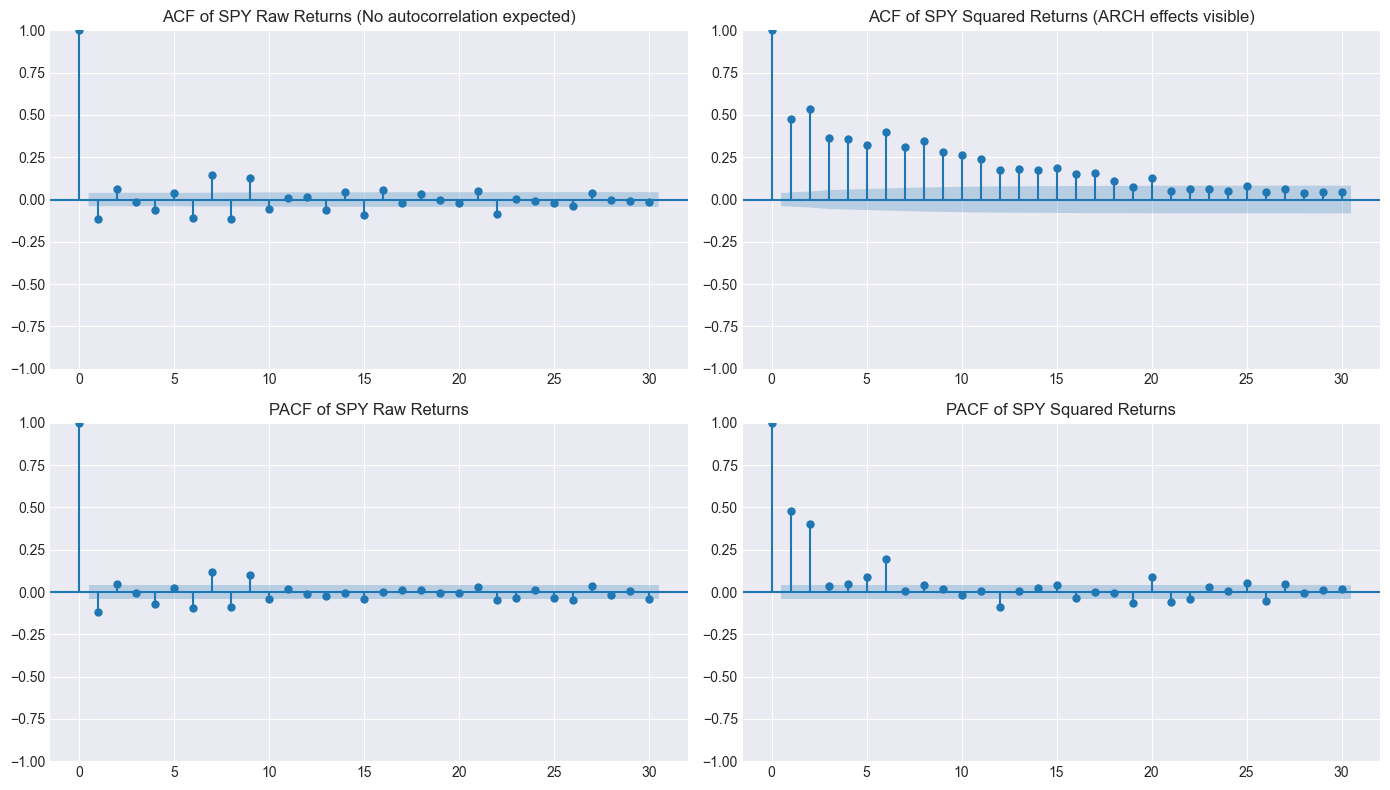

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(14, 8))

# SPY Raw Returns ACF
plot_acf(data['SPY']['Daily_Return'].dropna(), lags=30, ax=axes[0, 0])
axes[0, 0].set_title("ACF of SPY Raw Returns (No autocorrelation expected)")

# SPY Squared Returns ACF
plot_acf(data['SPY']['Daily_Return'].dropna() ** 2, lags=30, ax=axes[0, 1])
axes[0, 1].set_title("ACF of SPY Squared Returns (ARCH effects visible)")

# SPY Raw Returns PACF
plot_pacf(data['SPY']['Daily_Return'].dropna(), lags=30, ax=axes[1, 0])
axes[1, 0].set_title("PACF of SPY Raw Returns")

# SPY Squared Returns PACF
plot_pacf(data['SPY']['Daily_Return'].dropna() ** 2, lags=30, ax=axes[1, 1])
axes[1, 1].set_title("PACF of SPY Squared Returns")

plt.tight_layout()
plt.show()

## Experiment A Conclusion: Return Behaviour & Volatility Clustering

**1. Returns are not normally distributed.**
All assets exhibit significant fat tails (leptokurtosis) and negative skewness (especially in equities). The Jarque-Bera test overwhelmingly rejects normality. Therefore, risk models assuming a normal distribution will severely underestimate the probability of extreme market moves.

**2. Returns exhibit slight autocorrelation.**
Ljung-Box tests indicate significant autocorrelation in the raw daily returns of SPY, QQQ, IWM, and TLT (GLD acts as a pure random walk). While statistically significant, this signal is likely too small to be economically profitable once transaction costs are included. This will be tested in Experiment C.

**3. Volatility clusters strongly.**
The ARCH tests and ACF/PACF plots of squared returns provide overwhelming evidence of volatility clustering. This validates our starting hypothesis (H1): historical volatility contains highly predictive information about future volatility. 

**Next Steps:**
Given the strong ARCH effects, we will proceed to Experiment B (Volatility Prediction) to quantify how well rolling volatility, EWMA, and GARCH(1,1) can forecast future realized volatility.